In [39]:
import os
import zipfile
import urllib.request
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13

print("Libraries imported successfully.")

Libraries imported successfully.


In [40]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00360/AirQualityUCI.zip"
zip_path = "AirQualityUCI.zip"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as z:
  csv_name = next(name for name in z.namelist() if name.lower().endswith(".csv"))
  with z.open(csv_name) as f:
    df = pd.read_csv(f, sep=";", decimal=",", encoding="latin1")

                    # Remove empty trailing columns sometimes present in this file
df = df.dropna(axis=1, how="all")
df = df.loc[:, ~df.columns.astype(str).str.contains("^Unnamed")]
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9471, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [41]:
# Replace missing-value marker
df = df.replace(-200, np.nan)

# Standardize column names
df.columns = [str(c).strip() for c in df.columns]

if "Date" in df.columns and "Time" in df.columns:
    df["DateTime"] = pd.to_datetime(
        df["Date"].astype(str) + " " + df["Time"].astype(str),
        format="%d/%m/%Y %H.%M.%S",
        errors="coerce"
    )
    df["Hour"] = df["DateTime"].dt.hour
    df["Month"] = df["DateTime"].dt.month
    df["Weekday"] = df["DateTime"].dt.day_name()

                                            # Convert measurement columns to numeric where possible
exclude = {"Date", "Time", "DateTime", "Weekday"}
for col in df.columns:
  if col not in exclude:
    df[col] = pd.to_numeric(df[col], errors="coerce")

                                                        # Remove rows with invalid timestamps if timestamp column exists
if "DateTime" in df.columns:
  df = df.dropna(subset=["DateTime"]).sort_values("DateTime").reset_index(drop=True)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
pollutant_cols = [c for c in ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)", "NO(GT)", "PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)"] if c in df.columns]
weather_cols = [c for c in ["T", "RH", "AH"] if c in df.columns]

print("Cleaned shape:", df.shape)
print("Numeric columns:", numeric_cols)
print("Pollutant/sensor columns:", pollutant_cols)
print("Weather columns:", weather_cols)
display(df.head())

Cleaned shape: (9357, 19)
Numeric columns: ['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Hour', 'Month']
Pollutant/sensor columns: ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)']
Weather columns: ['T', 'RH', 'AH']


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,DateTime,Hour,Month,Weekday
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00,18.0,3.0,Wednesday
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00,19.0,3.0,Wednesday
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00,20.0,3.0,Wednesday
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00,21.0,3.0,Wednesday
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00,22.0,3.0,Wednesday


In [42]:
display(df.info())
display(df.describe(include="all").T.head(25))
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   object        
 1   Time           9357 non-null   object        
 2   CO(GT)         7674 non-null   float64       
 3   PT08.S1(CO)    8991 non-null   float64       
 4   NMHC(GT)       914 non-null    float64       
 5   C6H6(GT)       8991 non-null   float64       
 6   PT08.S2(NMHC)  8991 non-null   float64       
 7   NOx(GT)        7718 non-null   float64       
 8   PT08.S3(NOx)   8991 non-null   float64       
 9   NO2(GT)        7715 non-null   float64       
 10  PT08.S4(NO2)   8991 non-null   float64       
 11  PT08.S5(O3)    8991 non-null   float64       
 12  T              8991 non-null   float64       
 13  RH             8991 non-null   float64       
 14  AH             8991 non-null   float64       
 15  DateTime       9357 n

None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Date,9357,391,03/04/2005,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9357,24,18.00.00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),7674.0,NaN,NaN,NaN,2.15275,0.1,1.1,1.8,2.9,11.9,1.453252
PT08.S1(CO),8991.0,NaN,NaN,NaN,1099.833166,647.0,937.0,1063.0,1231.0,2040.0,217.080037
NMHC(GT),914.0,NaN,NaN,NaN,218.811816,7.0,67.0,150.0,297.0,1189.0,204.459921
C6H6(GT),8991.0,NaN,NaN,NaN,10.083105,0.1,4.4,8.2,14.0,63.7,7.44982
PT08.S2(NMHC),8991.0,NaN,NaN,NaN,939.153376,383.0,734.5,909.0,1116.0,2214.0,266.831429
NOx(GT),7718.0,NaN,NaN,NaN,246.896735,2.0,98.0,180.0,326.0,1479.0,212.979168
PT08.S3(NOx),8991.0,NaN,NaN,NaN,835.493605,322.0,658.0,806.0,969.5,2683.0,256.81732
NO2(GT),7715.0,NaN,NaN,NaN,113.091251,2.0,78.0,109.0,142.0,340.0,48.370108


Missing values by column:


,missing_count
NMHC(GT),8443
CO(GT),1683
NO2(GT),1642
NOx(GT),1639
T,366
PT08.S5(O3),366
PT08.S1(CO),366
PT08.S2(NMHC),366
C6H6(GT),366
PT08.S3(NOx),366


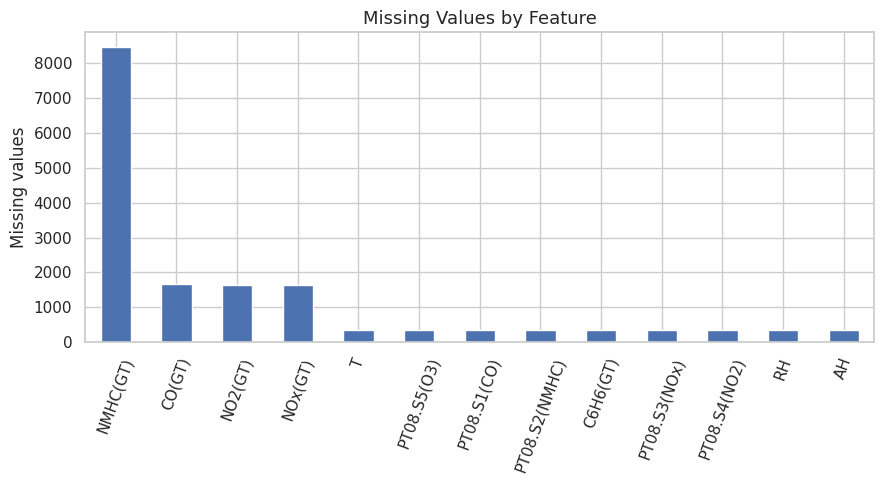

In [43]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing):
    missing.plot(kind="bar")
    plt.ylabel("Missing values"); plt.title("Missing Values by Feature"); plt.xticks(rotation=70); plt.tight_layout(); plt.show()
else:
  print("No missing values found.")

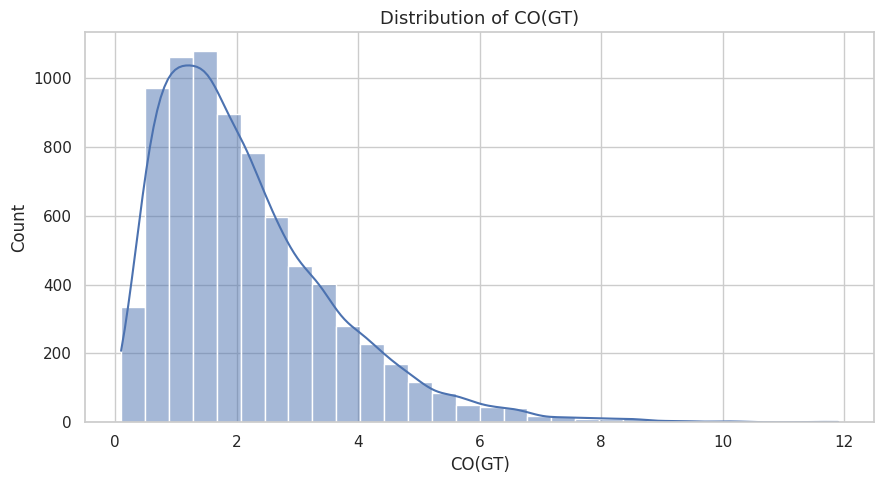

In [44]:
col = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
sns.histplot(data=df, x=col, kde=True, bins=30)
plt.title(f"Distribution of {col}"); plt.tight_layout(); plt.show()

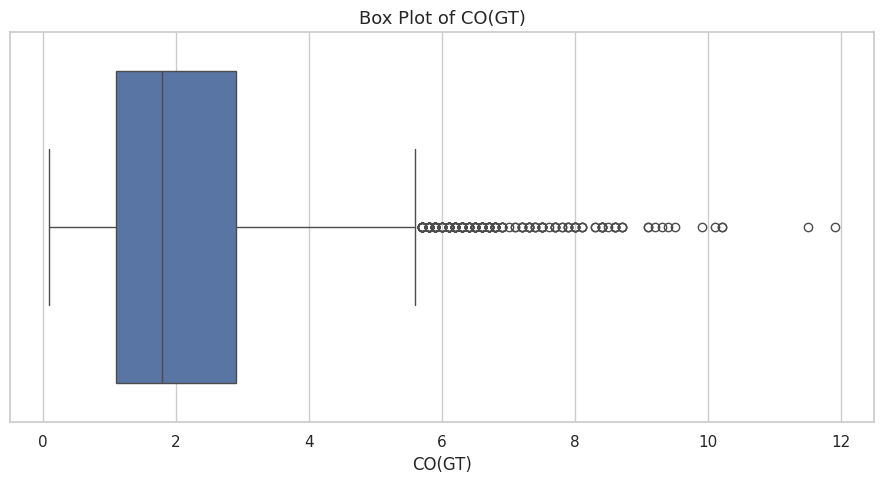

In [45]:
col = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
sns.boxplot(data=df, x=col)
plt.title(f"Box Plot of {col}"); plt.tight_layout(); plt.show()

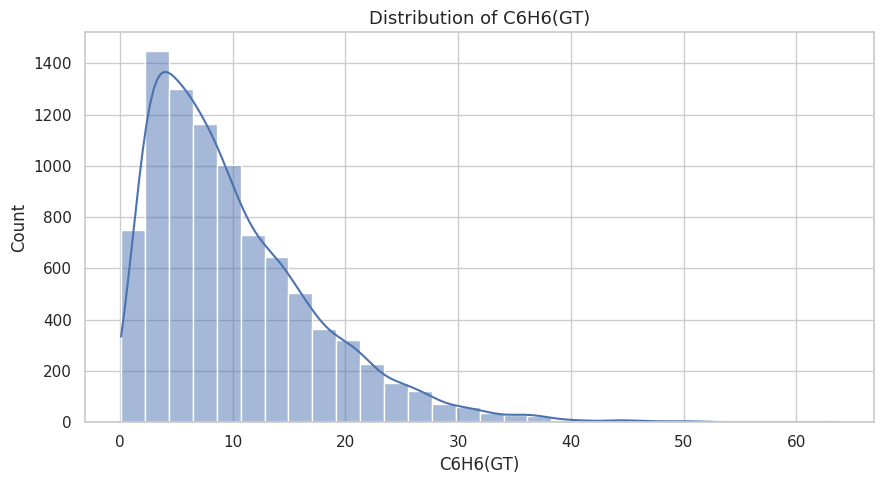

In [46]:
col = "C6H6(GT)" if "C6H6(GT)" in df.columns else numeric_cols[min(1, len(numeric_cols)-1)]
sns.histplot(data=df, x=col, kde=True, bins=30)
plt.title(f"Distribution of {col}"); plt.tight_layout(); plt.show()

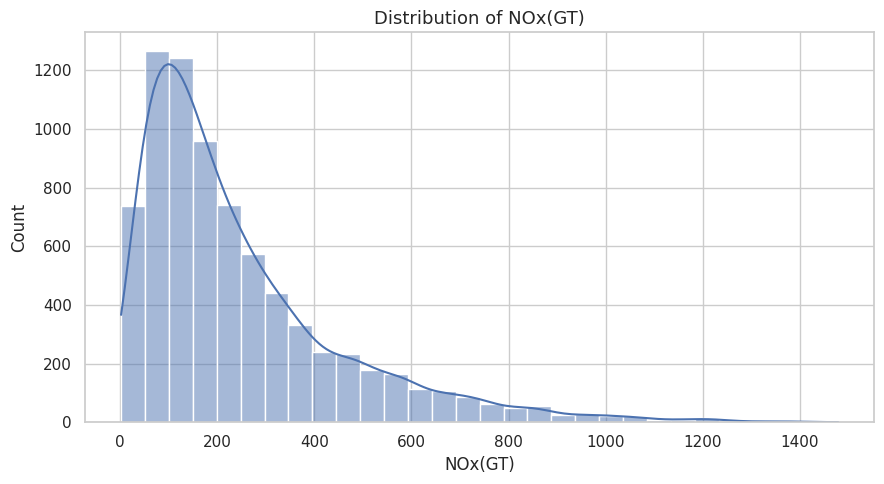

In [47]:
col = "NOx(GT)" if "NOx(GT)" in df.columns else numeric_cols[min(2, len(numeric_cols)-1)]
sns.histplot(data=df, x=col, kde=True, bins=30)
plt.title(f"Distribution of {col}"); plt.tight_layout(); plt.show()

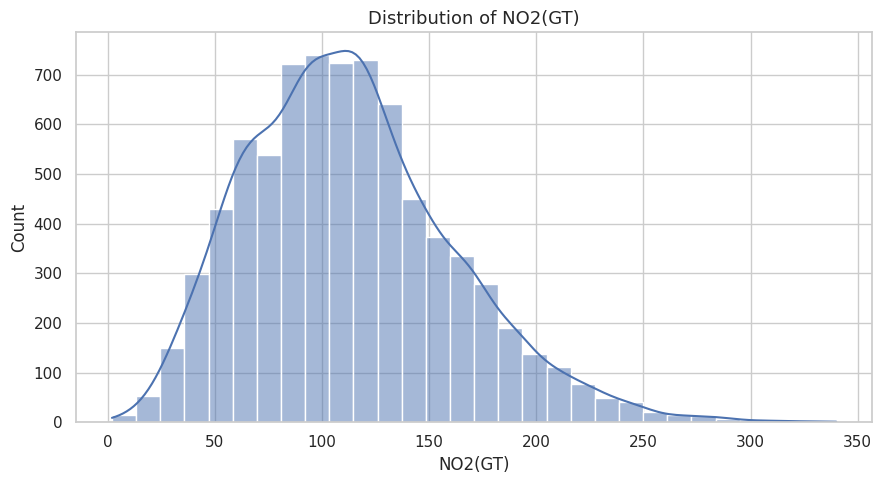

In [48]:
col = "NO2(GT)" if "NO2(GT)" in df.columns else numeric_cols[min(3, len(numeric_cols)-1)]
sns.histplot(data=df, x=col, kde=True, bins=30)
plt.title(f"Distribution of {col}"); plt.tight_layout(); plt.show()

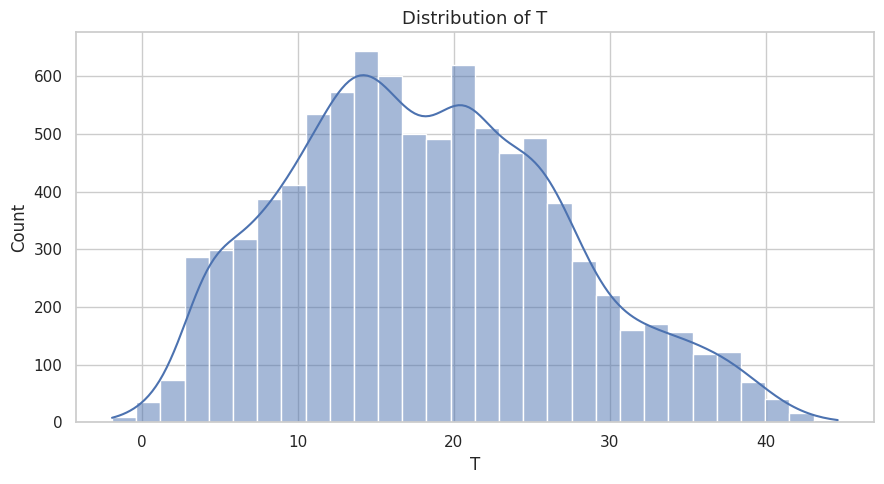

In [49]:
col = "T" if "T" in df.columns else numeric_cols[-1]
sns.histplot(data=df, x=col, kde=True, bins=30)
plt.title(f"Distribution of {col}"); plt.tight_layout(); plt.show()

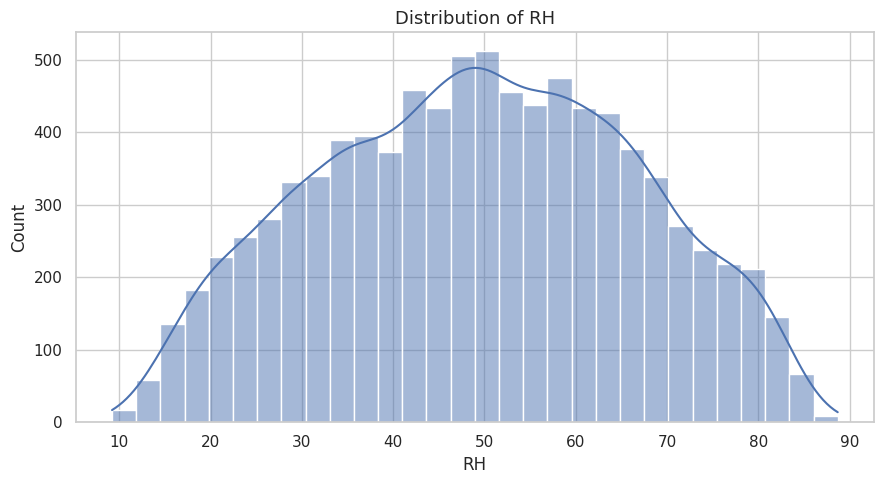

In [50]:
col = "RH" if "RH" in df.columns else numeric_cols[-1]
sns.histplot(data=df, x=col, kde=True, bins=30)
plt.title(f"Distribution of {col}"); plt.tight_layout(); plt.show()

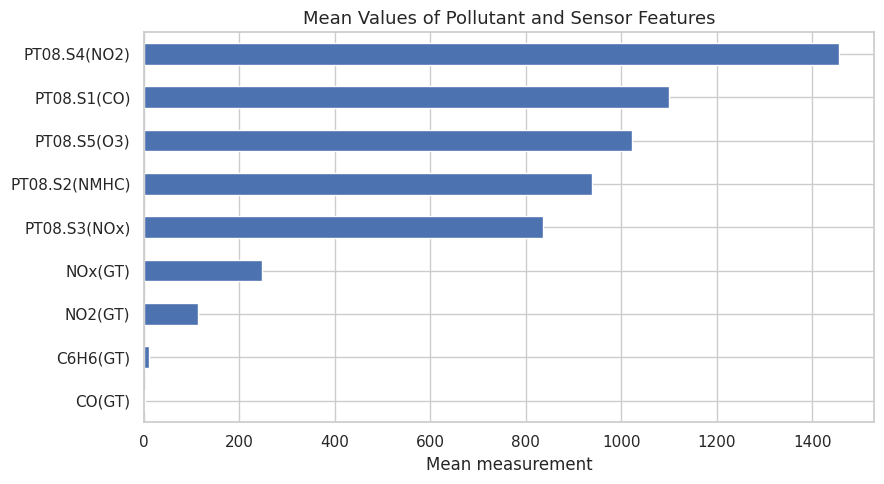

In [51]:
cols = [c for c in pollutant_cols if df[c].notna().any()]
if cols:
    df[cols].mean().sort_values().plot(kind="barh")
    plt.xlabel("Mean measurement"); plt.title("Mean Values of Pollutant and Sensor Features"); plt.tight_layout(); plt.show()
else:
    print("No pollutant columns available.")

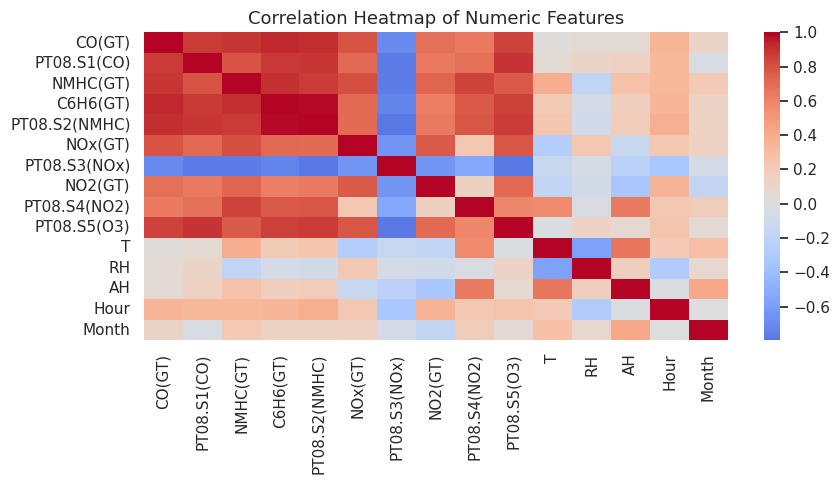

In [52]:
corr = df[numeric_cols].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Features"); plt.tight_layout(); plt.show()

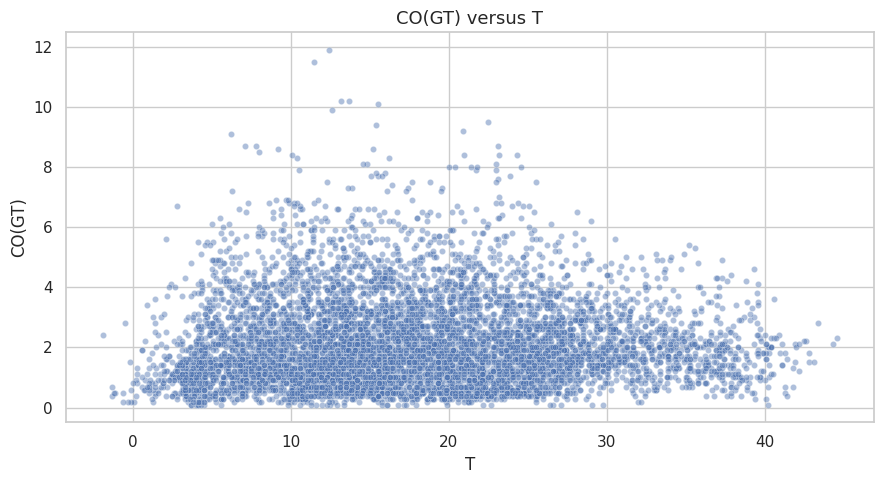

In [53]:
x = "T" if "T" in df.columns else numeric_cols[-1]
y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
sns.scatterplot(data=df, x=x, y=y, alpha=.45, s=20)
plt.title(f"{y} versus {x}"); plt.tight_layout(); plt.show()

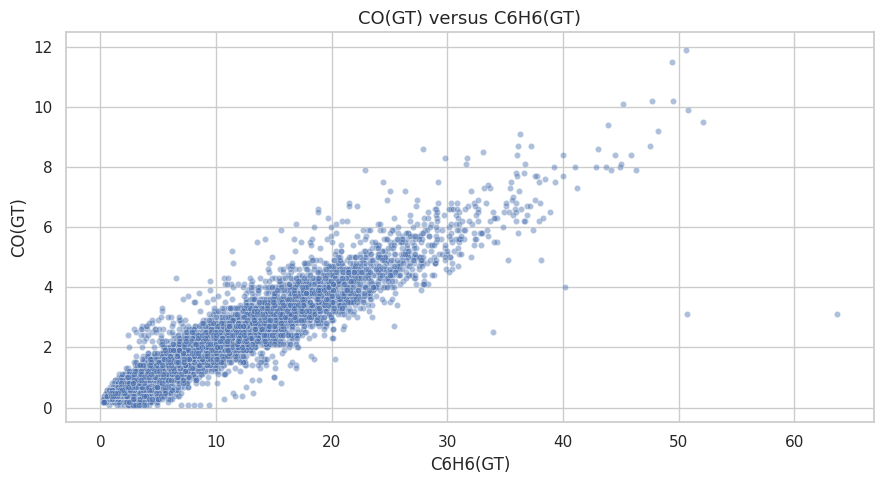

In [54]:
x = "C6H6(GT)" if "C6H6(GT)" in df.columns else numeric_cols[min(1, len(numeric_cols)-1)]
y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
sns.scatterplot(data=df, x=x, y=y, alpha=.45, s=20)
plt.title(f"{y} versus {x}"); plt.tight_layout(); plt.show()

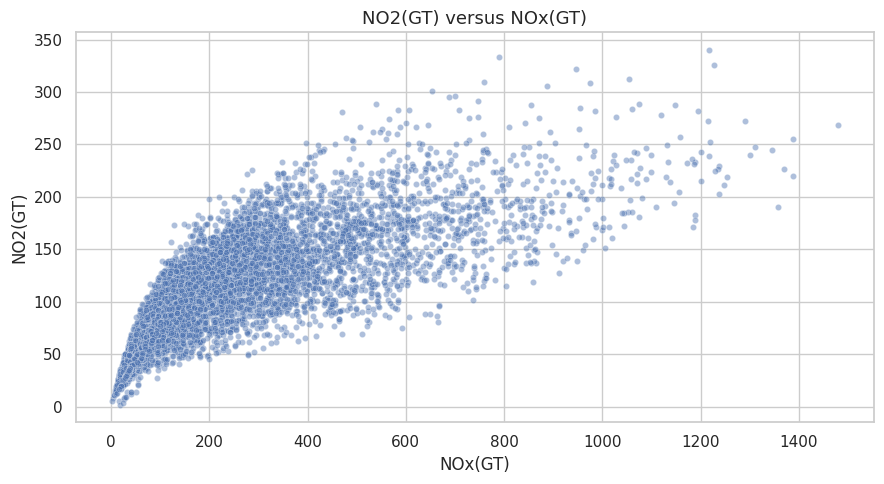

In [55]:
x = "NOx(GT)" if "NOx(GT)" in df.columns else numeric_cols[min(2, len(numeric_cols)-1)]
y = "NO2(GT)" if "NO2(GT)" in df.columns else numeric_cols[min(3, len(numeric_cols)-1)]
sns.scatterplot(data=df, x=x, y=y, alpha=.45, s=20)
plt.title(f"{y} versus {x}"); plt.tight_layout(); plt.show()

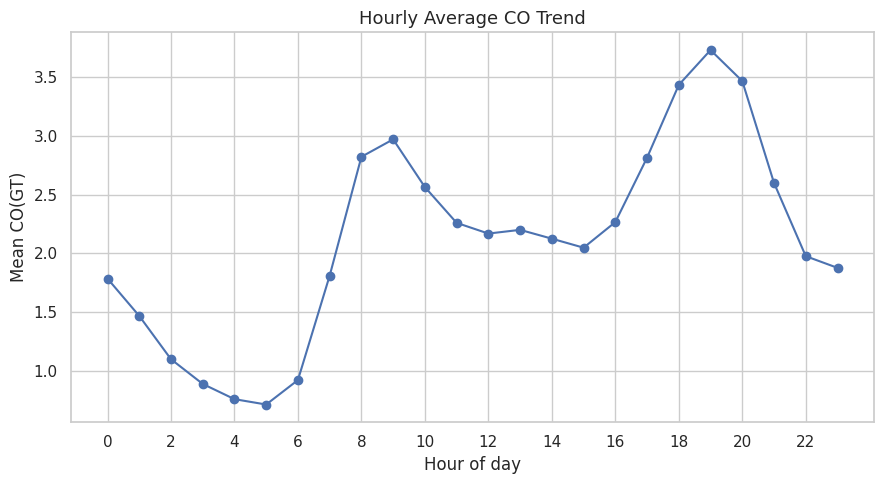

In [56]:
if "Hour" in df.columns:
      y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
      df.groupby("Hour")[y].mean().plot(marker="o")
      plt.xlabel("Hour of day"); plt.ylabel(f"Mean {y}"); plt.title("Hourly Average CO Trend"); plt.xticks(range(0,24,2)); plt.tight_layout(); plt.show()
else: print("Hour feature unavailable.")

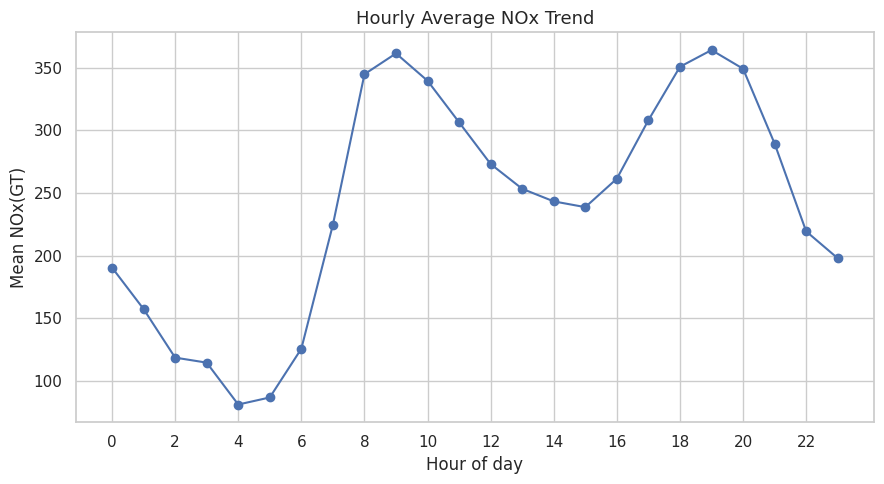

In [57]:
if "Hour" in df.columns:
      y = "NOx(GT)" if "NOx(GT)" in df.columns else numeric_cols[min(2, len(numeric_cols)-1)]
      df.groupby("Hour")[y].mean().plot(marker="o")
      plt.xlabel("Hour of day"); plt.ylabel(f"Mean {y}"); plt.title("Hourly Average NOx Trend"); plt.xticks(range(0,24,2)); plt.tight_layout(); plt.show()
else: print("Hour feature unavailable.")

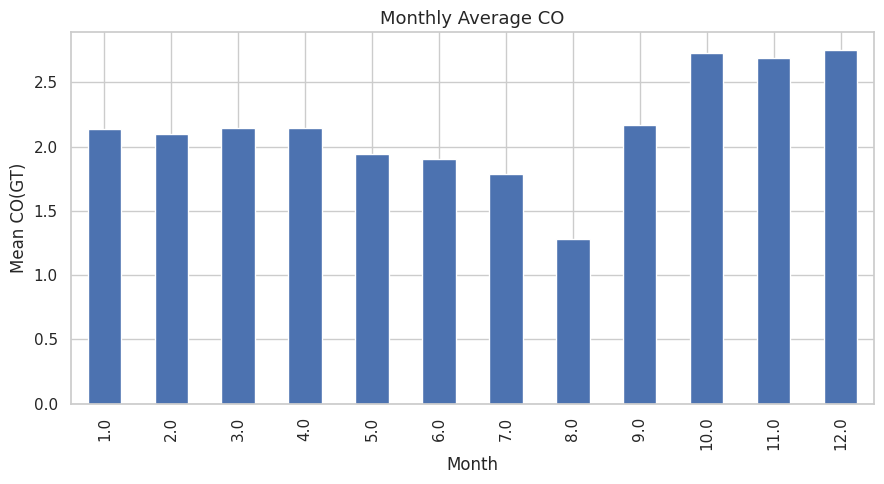

In [58]:
if "Month" in df.columns:
      y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
      df.groupby("Month")[y].mean().plot(kind="bar")
      plt.xlabel("Month"); plt.ylabel(f"Mean {y}"); plt.title("Monthly Average CO"); plt.tight_layout(); plt.show()
else: print("Month feature unavailable.")

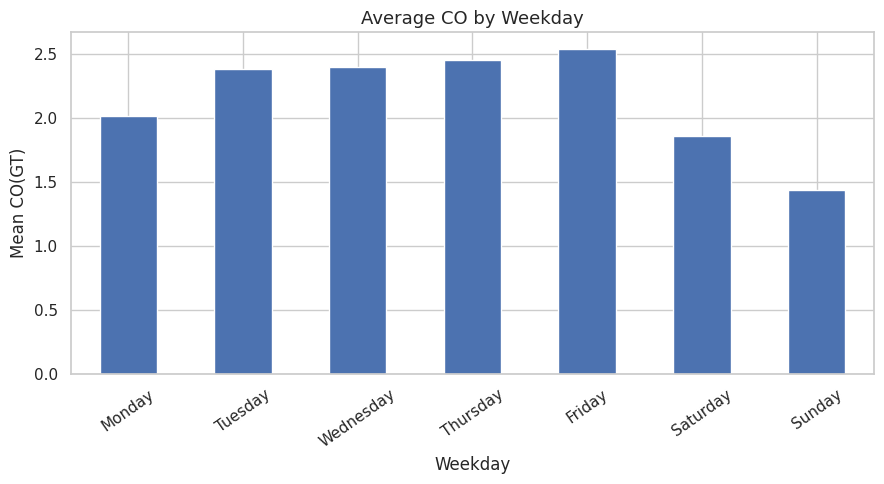

In [59]:
if "Weekday" in df.columns:
      y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
      order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
      df.groupby("Weekday")[y].mean().reindex(order).dropna().plot(kind="bar")
      plt.ylabel(f"Mean {y}"); plt.title("Average CO by Weekday"); plt.xticks(rotation=35); plt.tight_layout(); plt.show()
else: print("Weekday feature unavailable.")

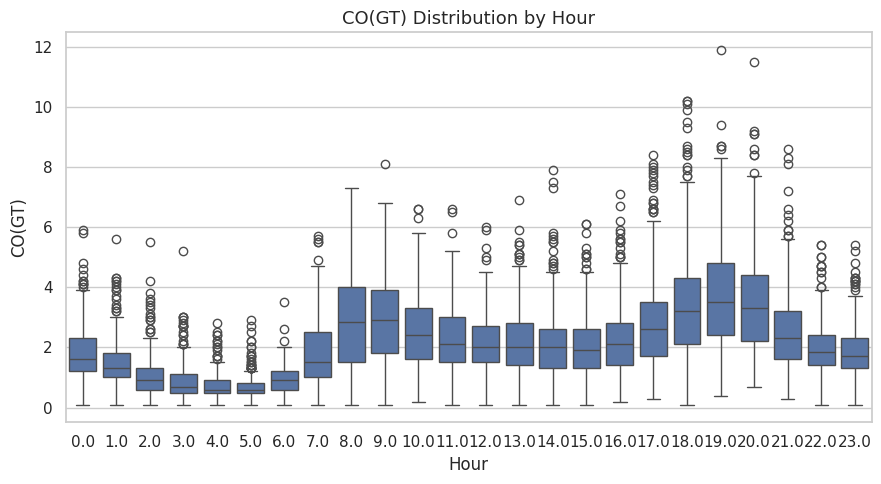

In [60]:
if "Hour" in df.columns:
      y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
      sns.boxplot(data=df, x="Hour", y=y)
      plt.title(f"{y} Distribution by Hour"); plt.tight_layout(); plt.show()
else: print("Hour feature unavailable.")

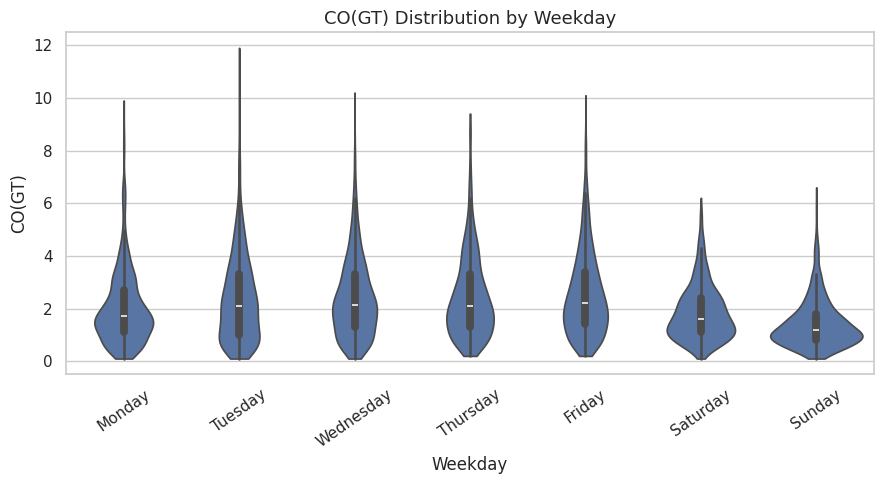

In [61]:
if "Weekday" in df.columns:
      y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
      order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
      sns.violinplot(data=df, x="Weekday", y=y, order=order, cut=0)
      plt.title(f"{y} Distribution by Weekday"); plt.xticks(rotation=35); plt.tight_layout(); plt.show()
else: print("Weekday feature unavailable.")

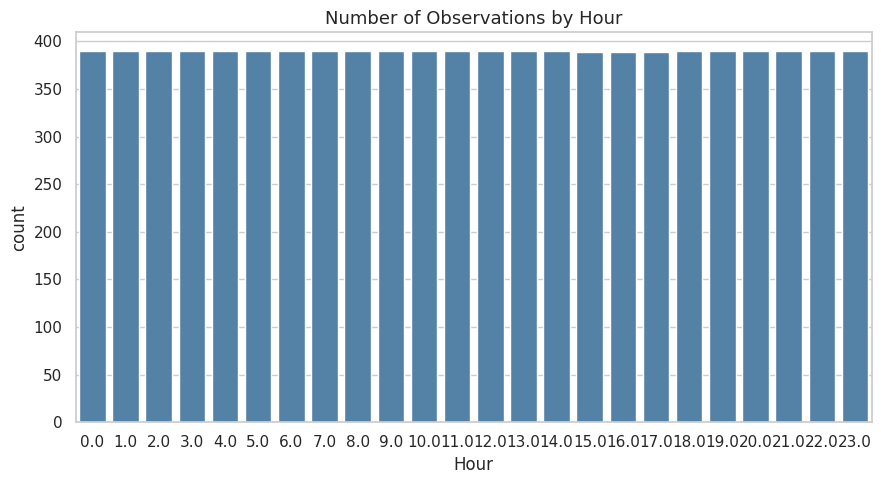

In [62]:
if "Hour" in df.columns:
      sns.countplot(data=df, x="Hour", color="steelblue")
      plt.title("Number of Observations by Hour"); plt.tight_layout(); plt.show()
else: print("Hour feature unavailable.")

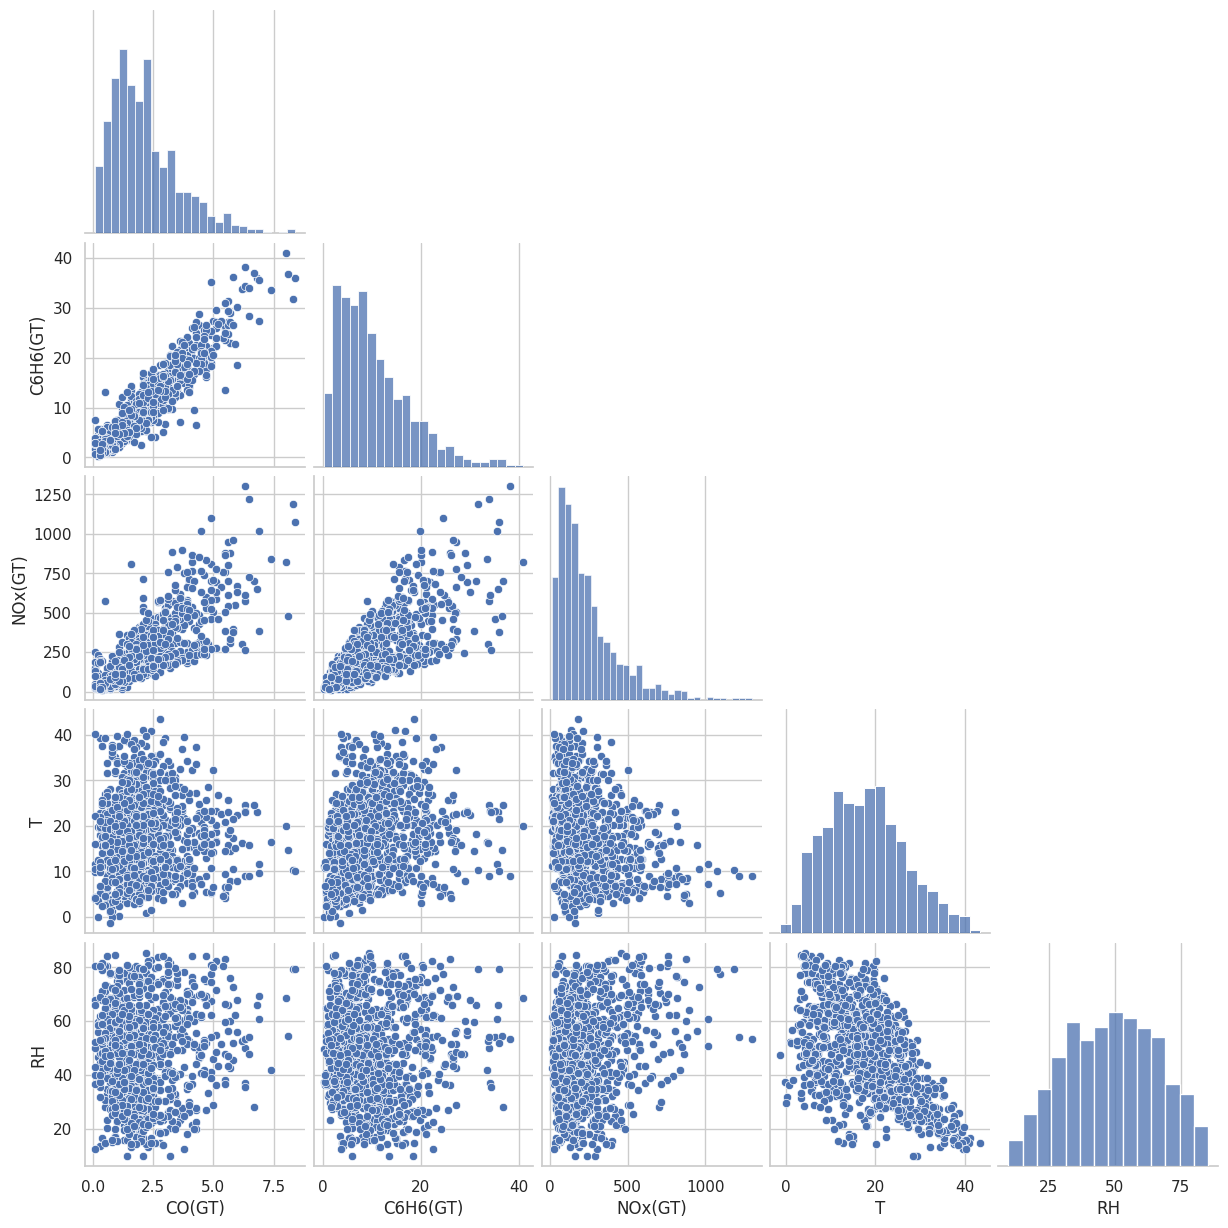

In [63]:
pair_cols = [c for c in ["CO(GT)", "C6H6(GT)", "NOx(GT)", "T", "RH"] if c in df.columns]
if len(pair_cols) >= 2:
    sample = df[pair_cols].dropna()
    if len(sample) > 1000: sample = sample.sample(1000, random_state=42)
    sns.pairplot(sample, corner=True, diag_kind="hist")
    plt.show()
else: print("Not enough key variables for pair plot.")

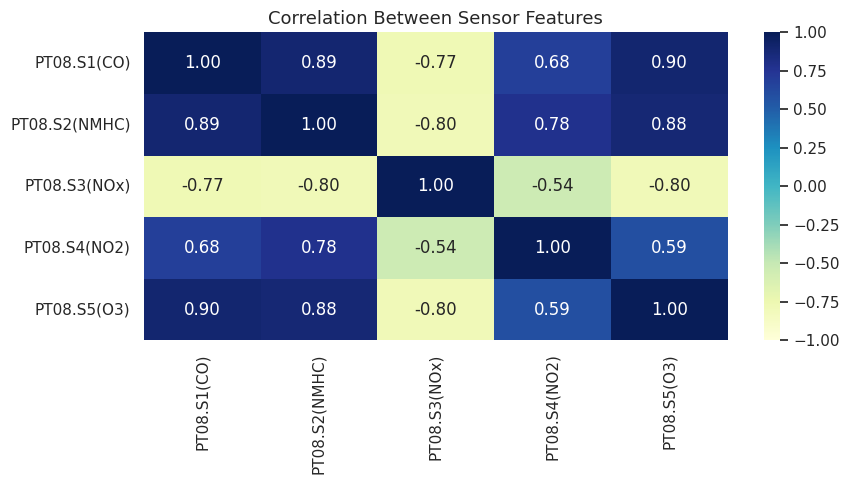

In [64]:
sensor_cols = [c for c in df.columns if c.startswith("PT08")]
if len(sensor_cols) >= 2:
    sns.heatmap(df[sensor_cols].corr(), annot=True, fmt=".2f", cmap="YlGnBu", vmin=-1, vmax=1)
    plt.title("Correlation Between Sensor Features"); plt.tight_layout(); plt.show()
else: print("Sensor columns unavailable.")

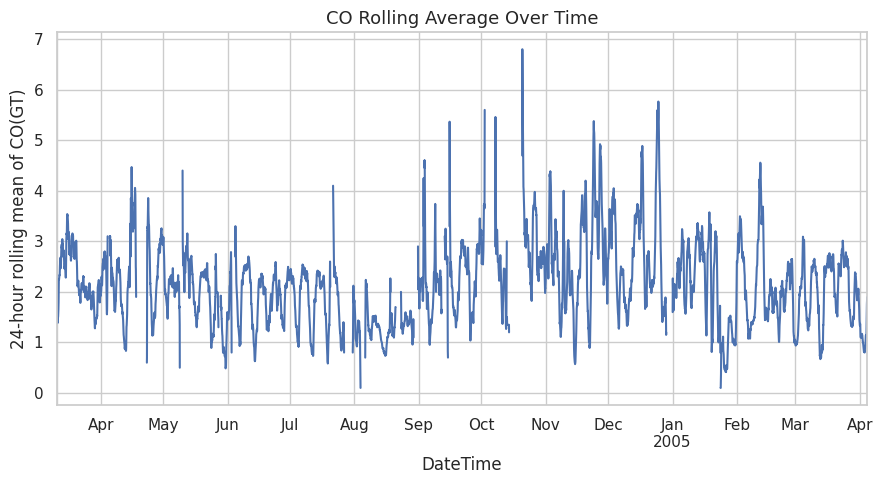

In [65]:
if "DateTime" in df.columns:
      y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
      temp = df.set_index("DateTime")[y].sort_index()
      temp.rolling("24H", min_periods=1).mean().plot()
      plt.ylabel(f"24-hour rolling mean of {y}"); plt.title("CO Rolling Average Over Time"); plt.tight_layout(); plt.show()
else: print("DateTime feature unavailable.")

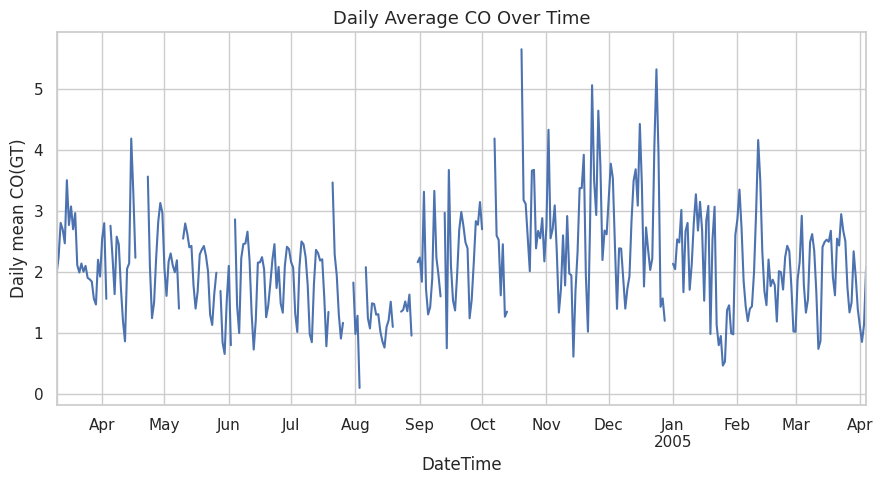

In [66]:
if "DateTime" in df.columns:
      y = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
      daily = df.set_index("DateTime")[y].resample("D").mean()
      daily.plot()
      plt.ylabel(f"Daily mean {y}"); plt.title("Daily Average CO Over Time"); plt.tight_layout(); plt.show()
else: print("DateTime feature unavailable.")

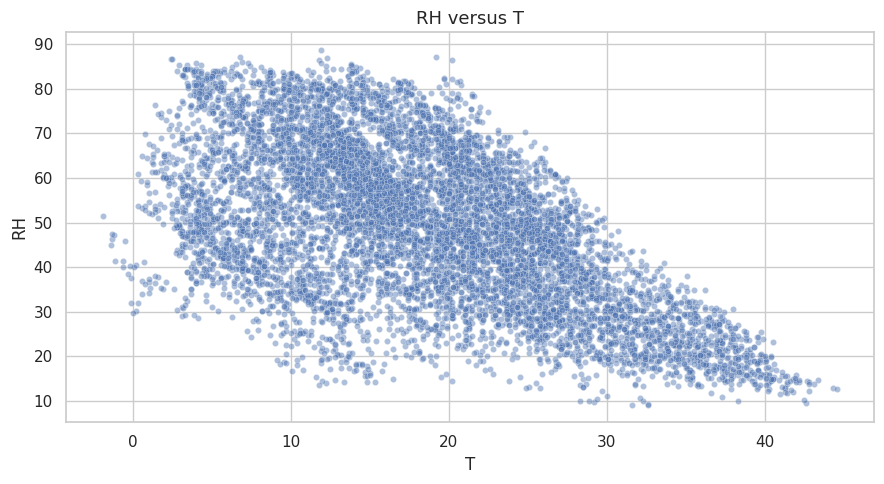

In [67]:
x = "T" if "T" in df.columns else numeric_cols[-1]
y = "RH" if "RH" in df.columns else numeric_cols[-2]
sns.scatterplot(data=df, x=x, y=y, alpha=.45, s=20)
plt.title(f"{y} versus {x}"); plt.tight_layout(); plt.show()

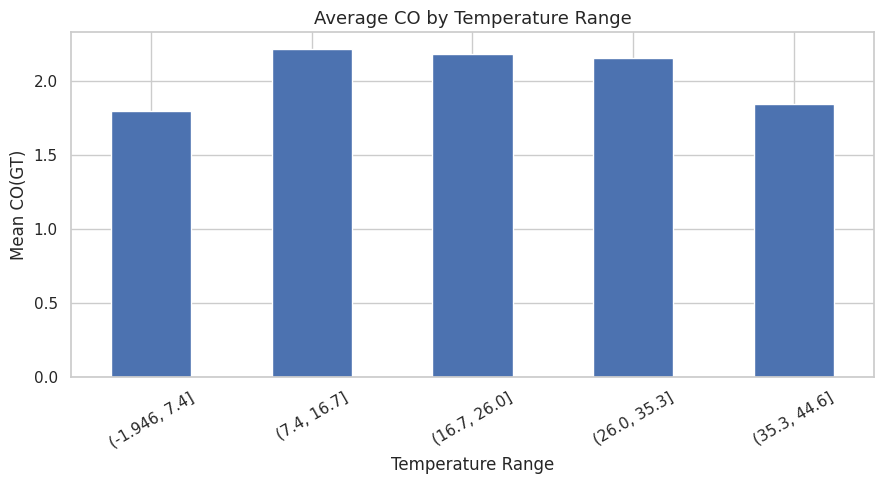

In [68]:
temp_col = "T" if "T" in df.columns else numeric_cols[-1]
co_col = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
temp_df = df[[temp_col, co_col]].dropna().copy()
temp_df["Temperature Range"] = pd.cut(temp_df[temp_col], bins=5)
temp_df.groupby("Temperature Range", observed=False)[co_col].mean().plot(kind="bar")
plt.ylabel(f"Mean {co_col}"); plt.title("Average CO by Temperature Range"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

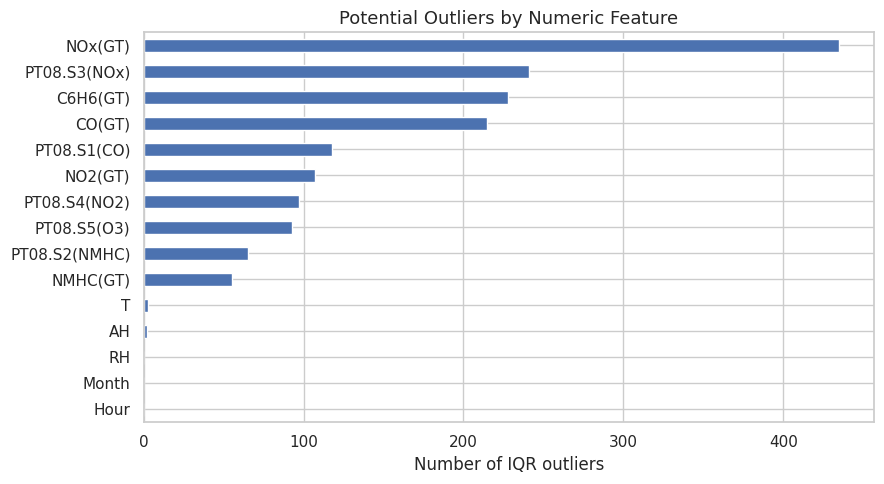

In [69]:
outlier_counts = {}
for c in numeric_cols:
    s = df[c].dropna()
    if len(s):
      q1, q3 = s.quantile([0.25, 0.75])
      iqr = q3 - q1
      outlier_counts[c] = int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())
pd.Series(outlier_counts).sort_values().plot(kind="barh")
plt.xlabel("Number of IQR outliers"); plt.title("Potential Outliers by Numeric Feature"); plt.tight_layout(); plt.show()

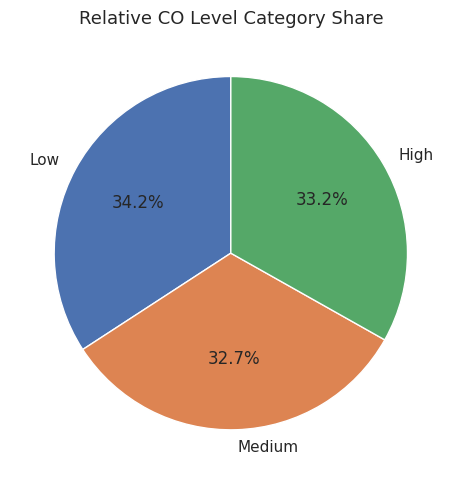

In [70]:
co_col = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
s = df[co_col].dropna()
if len(s) and s.nunique() >= 3:
    labels = ["Low", "Medium", "High"]
    df["CO_Level_Category"] = pd.qcut(df[co_col], q=3, labels=labels, duplicates="drop")
    df["CO_Level_Category"].value_counts().sort_index().plot(kind="pie", autopct="%1.1f%%", startangle=90)
    plt.ylabel(""); plt.title("Relative CO Level Category Share"); plt.tight_layout(); plt.show()
else: print("Not enough distinct CO values to categorize.")

MAE: 0.3
RMSE: 0.472
R²: 0.893


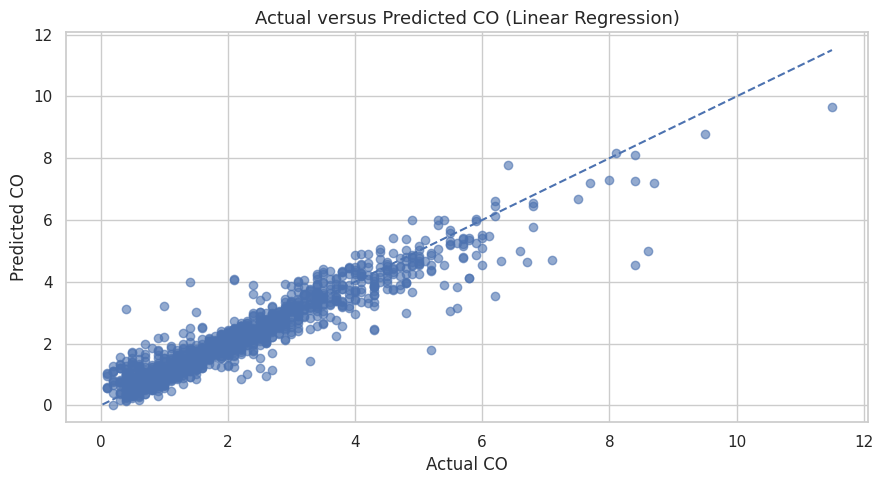

In [71]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target = "CO(GT)" if "CO(GT)" in df.columns else numeric_cols[0]
features = [c for c in numeric_cols if c != target and c not in ["Hour", "Month"]]
model_data = df[features + [target]].dropna(subset=[target]).copy()
# Keep only features with at least some non-missing values
features = [c for c in features if model_data[c].notna().any()]
X = model_data[features]
y = model_data[target]

if len(model_data) >= 20 and len(features) >= 1:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    print("MAE:", round(mean_absolute_error(y_test, predictions), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 3))
    print("R²:", round(r2_score(y_test, predictions), 3))
    plt.scatter(y_test, predictions, alpha=.6)
    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())
    plt.plot([low, high], [low, high], linestyle="--")
    plt.xlabel("Actual CO"); plt.ylabel("Predicted CO")
    plt.title("Actual versus Predicted CO (Linear Regression)")
    plt.tight_layout(); plt.show()
else:
  print("Not enough complete target data/features for the baseline model.")